# 35. Multi-window truncated BPTT calibration rollout, uniform large-angle faults (three sensors)

**Source:** notebook 34, preserving its data splits, model, fault sampling, calibration update semantics, optimizer, checkpoint structure, and evaluation. The change is in the **gradient horizon** rather than the rollout horizon.

- Each example remains a contiguous sequence of `SEQUENCE_LENGTH=8` five-second windows. The initial calibration is perturbed once; each correction is carried into the next window.
- **True multi-window BPTT:** accumulate post-update losses over `BPTT_HORIZON` connected windows, backpropagate the segment loss, and only then detach the calibration state. This allows the gradient of a later loss to reach earlier correction predictions within the same segment. The optimizer still steps **once per full sequence batch**.
- Default `BPTT_HORIZON=3`, `SEQUENCE_BATCH_SIZE=4`. To test full eight-window BPTT, set `BPTT_HORIZON=8`, `SEQUENCE_BATCH_SIZE=2`, after checking VRAM on a smoke batch.
- All 170° uniform rotation, ±500 ms uniform clock, one-sensor selection, fault modes, 25% axis-aligned perturbations, and post-update Smooth L1 loss remain **unchanged** from notebook 34.
- Healthy sensors and translations are held fixed throughout the rollout; identifying a faulty sensor is not part of this experiment.
- The new gradient smoke test verifies nonzero **cross-window** gradient through the model's actual physical calibration path, not merely local model gradients.
- Validation and checkpoint comparison still run full eight-window forward rollouts; BPTT truncation affects training gradients only.

**Memory and time:** Activation memory grows roughly with batch size times connected horizon, not exactly linearly because attention and allocator effects contribute. Full `H=8, B=2` may fit but can be slower per epoch because of many more small batches; `H=3, B=4` is a practical first check. **Horizon ≠ epoch coverage:** training still uses all eligible chronological sequence chunks.


## 1. Imports and repository root

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, KAISTSequenceChunkDataset, build_kaist_sequence_specs, collate_kaist_sequence_chunks, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)

from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from obscalib.geometry.lie import so3_exp

Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment configuration

In [2]:
RUN_NAME = "kaist_pooled_calibration_paired_002.19_multistep_tbptt"
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.16_correction_only"  # Or 002.17 for an explicit ablation.
INITIAL_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"
RESUME_TRAINING = False
RESUME_TRAINING_CHECKPOINT = ROOT / "runs" / RUN_NAME / "last.pt"

RANDOM_SEED = 12345
TRAIN_SEQUENCE_SEED = 23456
VALIDATION_SEQUENCE_SEED = 34567
TEST_SEQUENCE_SEED = 45678

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
NUM_WORKERS = 0

# Eight physical windows per rollout. BPTT_HORIZON controls connected autograd steps only.
# Memory approximately scales with (SEQUENCE_BATCH_SIZE * BPTT_HORIZON).
# Try H=8, B=2 only after the default H=3, B=4 passes the gradient and memory smoke tests.
SEQUENCE_LENGTH = 8
BPTT_HORIZON = 6
TRAIN_SEQUENCE_STRIDE = SEQUENCE_LENGTH
VAL_SEQUENCE_STRIDE = SEQUENCE_LENGTH
TEST_SEQUENCE_STRIDE = SEQUENCE_LENGTH
SEQUENCE_BATCH_SIZE = 2
SEQUENCE_EVAL_BATCH_SIZE = 16

NUM_EPOCHS = 200
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 8
CHECKPOINT_EVERY_EPOCHS = 3
RUN_FULL_TRAINING = True
MAX_TRAIN_BATCHES = None  # None uses every training chunk; small integer for debugging only.
MAX_VAL_BATCHES = None

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.0
NUM_SUMMARY_TOKENS = 1
POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.0
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.0
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.0

ROTATION_LOSS_SCALE_RAD = np.deg2rad(5.0)
TIME_OFFSET_LOSS_SCALE_S = 0.050
ROTATION_LOSS_WEIGHT = 2.0
TIME_OFFSET_LOSS_WEIGHT = 1.0
ROTATION_MAX_RAD = np.deg2rad(170.0)
TIME_OFFSET_MAX_S = 0.500
# One magnitude distribution for all rotation and clock faults; fault-type mix is separate.
FAULT_TYPE_PROBABILITIES = {"rotation_only": 0.25, "tau_only": 0.25, "combined": 0.50}
AXIS_ALIGNED_ROTATION_PROBABILITY = 0.25  # Directional mix, NOT a second magnitude distribution.
ROTATION_UPDATE_GAIN = 1.0
TAU_UPDATE_GAIN = 1.0
MAX_ROTATION_STEP_DEG = None  # E.g. 45.0 for a controller ablation; default raw learned update.
MAX_TAU_STEP_MS = None
CONVERGENCE_ROTATION_DEG = 5.0
CONVERGENCE_TAU_MS = 15.0

# Keep the same KAIST reference calibration throughout a sequence. Applying independent
# true-calibration augmentation at every step would create fictitious repeated faults.
ENABLE_FRAME_RANDOMIZATION = False
ENABLE_TRUE_CALIBRATION_AUGMENTATION = False
ENABLE_MEASUREMENT_NOISE = False
ENABLE_SAMPLING_RATE_AUGMENTATION = False

if not INITIAL_CHECKPOINT.is_file() and not RESUME_TRAINING:
    raise FileNotFoundError(f"Cannot initialize model from {INITIAL_CHECKPOINT}")
assert set(FAULT_TYPE_PROBABILITIES) == {"rotation_only", "tau_only", "combined"}
assert np.isclose(sum(FAULT_TYPE_PROBABILITIES.values()), 1.0)
assert 0 < ROTATION_MAX_RAD < np.pi
assert SEQUENCE_LENGTH > 1 and SEQUENCE_BATCH_SIZE > 0
assert 1 <= BPTT_HORIZON <= SEQUENCE_LENGTH, "BPTT horizon must fit within the sequence."

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("Run:", RUN_NAME, "| model initialization:", INITIAL_CHECKPOINT)
print("Uniform rotation magnitude: 0-170 deg; time offset: +/-500 ms")
print("Fault types:", FAULT_TYPE_PROBABILITIES)
print(f"Rollout steps: {SEQUENCE_LENGTH} | connected BPTT horizon: {BPTT_HORIZON} | batch size: {SEQUENCE_BATCH_SIZE}")


Run: kaist_pooled_calibration_paired_002.19_multistep_tbptt | model initialization: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt
Uniform rotation magnitude: 0-170 deg; time offset: +/-500 ms
Fault types: {'rotation_only': 0.25, 'tau_only': 0.25, 'combined': 0.5}
Rollout steps: 8 | connected BPTT horizon: 6 | batch size: 2


## 3. KAIST rig and train/validation/test split (unchanged from notebook 33)

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)

train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())

KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

## 4. Chronological chunk loaders (adapted from notebook 06)

In [5]:
sequence_train_dataset = KAISTSequenceChunkDataset(train_dataset, sequence_length=SEQUENCE_LENGTH, sequence_stride=TRAIN_SEQUENCE_STRIDE)
sequence_val_dataset = KAISTSequenceChunkDataset(val_dataset, sequence_length=SEQUENCE_LENGTH, sequence_stride=VAL_SEQUENCE_STRIDE)
sequence_test_dataset = KAISTSequenceChunkDataset(test_dataset, sequence_length=SEQUENCE_LENGTH, sequence_stride=TEST_SEQUENCE_STRIDE)

sequence_train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
sequence_train_loader = DataLoader(sequence_train_dataset, batch_size=SEQUENCE_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, collate_fn=collate_kaist_sequence_chunks, generator=sequence_train_shuffle_generator)
sequence_val_loader = DataLoader(sequence_val_dataset, batch_size=SEQUENCE_EVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, collate_fn=collate_kaist_sequence_chunks)
sequence_test_loader = DataLoader(sequence_test_dataset, batch_size=SEQUENCE_EVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, collate_fn=collate_kaist_sequence_chunks)

for label, dataset, loader in (("train", sequence_train_dataset, sequence_train_loader), ("val", sequence_val_dataset, sequence_val_loader), ("test", sequence_test_dataset, sequence_test_loader)):
    print(f"{label}: {len(dataset)} sequence chunks, {len(loader)} sequence batches")

first_chunk_batch = collate_kaist_sequence_chunks([sequence_train_dataset[0]])
assert isinstance(first_chunk_batch, (tuple, list)) and len(first_chunk_batch) == SEQUENCE_LENGTH
assert all(tuple(step.current_calibration) == CALIBRATION_KEYS for step in first_chunk_batch)
print("Chronological sequence collator: PASS | steps:", len(first_chunk_batch))
del first_chunk_batch

train: 248 sequence chunks, 124 sequence batches
val: 51 sequence chunks, 4 sequence batches
test: 86 sequence chunks, 6 sequence batches
Chronological sequence collator: PASS | steps: 8


## 5. Same pretrained pooled Transformer and calibration head as notebook 33

In [6]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)

PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=128, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
        )
      )
    )
  )
  (pooler): CalibrationPooler(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQ

## 6. One uniform prior distribution, one faulty sensor per sequence

In [7]:
uniform_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=ROTATION_MAX_RAD, distribution=PerturbationDistribution.UNIFORM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.UNIFORM),
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)
uniform_prior_perturber = CalibrationPriorPerturber(uniform_prior_config)

def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)

def detach_calibration(states):
    return {key: CalibrationState(transform=state.transform.detach(), time_offset=state.time_offset.detach()) for key, state in states.items()}

def copy_calibration(states):
    return {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in states.items()}

def sample_rollout_initial_calibration(truth, generator):
    """Draw a uniform rotation/tau fault ONCE; select exactly one faulty sensor per item."""
    _, sample_xi, sample_tau = uniform_prior_perturber(truth, generator=generator)
    first_state = next(iter(truth.values()))
    B = first_state.transform.shape[0]
    device, dtype = first_state.transform.device, first_state.transform.dtype

    selected = {key: ((sample_xi[key][:, :3].norm(dim=-1) > 1e-9) | (sample_tau[key][:, 0].abs() > 1e-9)) for key in CALIBRATION_KEYS}
    assert torch.stack(tuple(selected.values()), dim=-1).sum(dim=-1).eq(1).all(), "The sampler must select exactly one sensor per sequence item."

    weights = torch.tensor([FAULT_TYPE_PROBABILITIES[name] for name in ("rotation_only", "tau_only", "combined")], dtype=dtype, device=device)
    modes = torch.multinomial(weights, B, replacement=True, generator=generator)
    axis_aligned = torch.rand(B, device=device, generator=generator) < AXIS_ALIGNED_ROTATION_PROBABILITY
    chosen_axis = torch.randint(0, 3, (B,), device=device, generator=generator)
    axis_sign = 2 * torch.randint(0, 2, (B,), device=device, generator=generator) - 1
    direction = F.one_hot(chosen_axis, num_classes=3).to(dtype=dtype) * axis_sign.to(dtype)[:, None]
    states = {}
    for key in CALIBRATION_KEYS:
        source_rotation = sample_xi[key][:, :3]
        axis_rotation = source_rotation.norm(dim=-1, keepdim=True) * direction
        dr = torch.where(axis_aligned[:, None], axis_rotation, source_rotation) * (modes != 1).to(dtype)[:, None]  # Drop rotation for tau-only.
        dt = sample_tau[key] * (modes != 0).to(dtype)[:, None]         # Drop tau for rotation-only.
        T = truth[key].transform.clone()
        T[:, :3, :3] = so3_exp(dr) @ T[:, :3, :3]
        # Preserve the original translation. Left-multiplying an SE(3) transform
        # would rotate its origin, although the rho head has never been trained.
        states[key] = CalibrationState(transform=T, time_offset=truth[key].time_offset + dt)

    return states, selected, modes

print(uniform_prior_config)

PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=2.9670597283903604, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=None, time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False)


### Verify sensor selection, bounds, and initial-state semantics

In [8]:
def verify_uniform_rollout_sampler():
    base = window_batch_to(collate_windows([train_dataset[int(i)] for i in np.linspace(0, len(train_dataset)-1, 8, dtype=int)]), DEVICE, dtype=MODEL_DTYPE)
    truth = base.current_calibration
    prior, selected, modes = sample_rollout_initial_calibration(truth, make_augmentation_generator(TRAIN_SEQUENCE_SEED+100))
    for key in CALIBRATION_KEYS:
        expected_t = truth[key].transform[:, :3, 3]
        torch.testing.assert_close(prior[key].transform[:, :3, 3], expected_t)
        Rdelta = prior[key].transform[:, :3, :3] @ truth[key].transform[:, :3, :3].transpose(-1, -2)
        # Relative rotation cannot exceed 170 degrees; trace/acos is only a diagnostic.
        angle = torch.rad2deg(torch.acos(((Rdelta.diagonal(dim1=-2,dim2=-1).sum(-1)-1)/2).clamp(-1,1)))
        assert (angle <= np.rad2deg(ROTATION_MAX_RAD) + .1).all()
        assert ((prior[key].time_offset-truth[key].time_offset).abs() <= TIME_OFFSET_MAX_S+1e-6).all()
        assert (angle[~selected[key]] < .2).all()
        torch.testing.assert_close(prior[key].time_offset[~selected[key]], truth[key].time_offset[~selected[key]])
    print("Sampler invariants: PASS | modes", {name: int((modes==j).sum()) for j,name in enumerate(FAULT_TYPE_PROBABILITIES)})
    del base

verify_uniform_rollout_sampler()

Sampler invariants: PASS | modes {'rotation_only': 2, 'tau_only': 0, 'combined': 6}


### Empirical single-uniform sampler coverage

Sampled fault modes: {'rotation_only': '25.3%', 'tau_only': '24.2%', 'combined': '50.4%'}
Fraction with rotation > 130 deg: 0.18359375


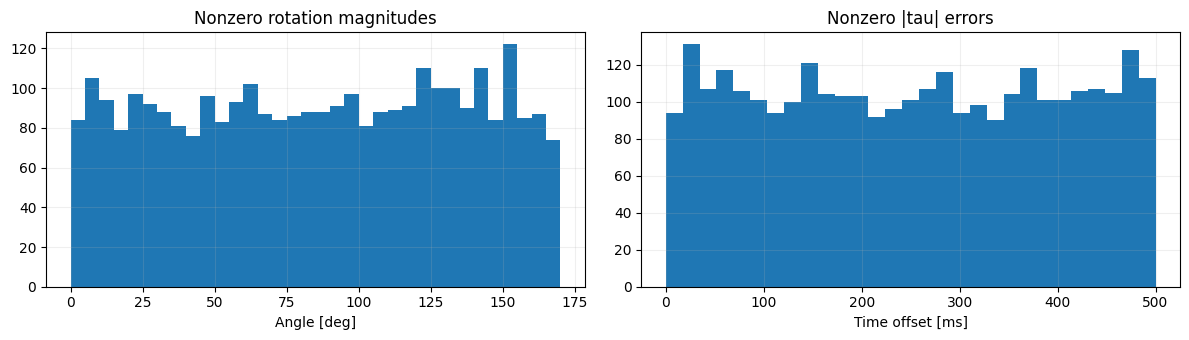

In [9]:
SAMPLER_CHECK_B = 4096
prototype = window_batch_to(collate_windows([train_dataset[0]]), DEVICE, dtype=MODEL_DTYPE).current_calibration
replicated_truth = {key: CalibrationState(transform=state.transform.repeat(SAMPLER_CHECK_B,1,1), time_offset=state.time_offset.repeat(SAMPLER_CHECK_B,1)) for key,state in prototype.items()}
replicated_prior, replicated_masks, sampled_modes = sample_rollout_initial_calibration(replicated_truth, make_augmentation_generator(TRAIN_SEQUENCE_SEED+120))
sampled_angles, sampled_taus = [], []
for key in CALIBRATION_KEYS:
    mask = replicated_masks[key]
    R = replicated_prior[key].transform[:, :3, :3] @ replicated_truth[key].transform[:, :3, :3].transpose(-1,-2)
    theta = torch.rad2deg(torch.acos(((R.diagonal(dim1=-2,dim2=-1).sum(-1)-1)/2).clamp(-1,1)))
    sampled_angles.append(theta[mask].cpu().numpy())
    sampled_taus.append((1000*(replicated_prior[key].time_offset - replicated_truth[key].time_offset).abs()[:,0])[mask].cpu().numpy())
all_angles = np.concatenate(sampled_angles)
all_taus = np.concatenate(sampled_taus)
print("Sampled fault modes:", {name: f"{100*(sampled_modes==i).float().mean():.1f}%" for i,name in enumerate(FAULT_TYPE_PROBABILITIES)})
print("Fraction with rotation > 130 deg:", (all_angles > 130).mean())
assert (all_angles <= 170.1).all() and (all_taus <= 500.01).all()
assert (all_angles > 130).mean() > 0.04, "Uniform large-angle tail unexpectedly sparse"
fig, axes = plt.subplots(1,2,figsize=(12,3.5))
axes[0].hist(all_angles[all_angles>0.1], bins=np.linspace(0,170,35))
axes[1].hist(all_taus[all_taus>0.01], bins=np.linspace(0,500,30))
axes[0].set(title="Nonzero rotation magnitudes", xlabel="Angle [deg]")
axes[1].set(title="Nonzero |tau| errors", xlabel="Time offset [ms]")
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()
del replicated_prior, replicated_truth, replicated_masks, prototype, sampled_angles, sampled_taus

## 7. Differentiable sensor-isolated correction update

In [10]:
from obscalib.calibration.context import calibration_state_to_context


def rollout_forward(window, states):
    """Use the SAME GeometryProcessor -> Tokenizer -> pooled model as notebook 33."""
    canonical = geometry_processor(window.streams, window.metadata, states)
    tokens = tokenizer(canonical, observability=None)
    if tokens.x.shape[-1] != TOKEN_INPUT_DIM or tuple(tokens.calibration_keys) != CALIBRATION_KEYS:
        raise ValueError("Rollout tokens have wrong dimension or calibration routing.")
    calibration_context = {key: calibration_state_to_context(states[key]) for key in CALIBRATION_KEYS}
    return model(tokens, calibration_context)


def apply_rollout_correction(states, output, selected):
    """Only selected faulty sensor may change R/tau. Preserve all translations."""
    updated = {}
    for key in CALIBRATION_KEYS:
        state, prediction = states[key], output.predictions[key]
        active = selected[key].to(device=state.transform.device)
        dphi = ROTATION_UPDATE_GAIN * prediction.delta_xi[:, :3]
        if MAX_ROTATION_STEP_DEG is not None:
            maximum = np.deg2rad(MAX_ROTATION_STEP_DEG)
            dphi = dphi * (maximum / dphi.norm(dim=-1, keepdim=True).clamp_min(1e-12)).clamp(max=1.0)
        dtau = TAU_UPDATE_GAIN * prediction.delta_tau
        if MAX_TAU_STEP_MS is not None:
            dtau = dtau.clamp(-MAX_TAU_STEP_MS/1000.0, MAX_TAU_STEP_MS/1000.0)

        T_updated = state.transform.clone()
        R_updated = so3_exp(dphi) @ state.transform[:, :3, :3]
        T_updated[:, :3, :3] = torch.where(active[:, None, None], R_updated, state.transform[:, :3, :3])
        tau_updated = torch.where(active[:, None], state.time_offset + dtau, state.time_offset)
        updated[key] = CalibrationState(transform=T_updated, time_offset=tau_updated)
    return updated


def assert_sequence_truth_consistent(step, truth, tol=1e-5):
    """Per-sequence ground-truth extrinsics/clocks must remain fixed."""
    for key in CALIBRATION_KEYS:
        if not torch.allclose(step.current_calibration[key].transform, truth[key].transform, atol=tol, rtol=0):
            raise RuntimeError(f"True {key} calibration changed within a sequence chunk.")
        if not torch.allclose(step.current_calibration[key].time_offset, truth[key].time_offset, atol=tol, rtol=0):
            raise RuntimeError(f"True {key} clock changed within a sequence chunk.")


def rollout_state_loss(truth, updated, selected):
    """Post-update active-sensor SO(3) and tau errors with a stable geodesic rotation loss."""
    first = next(iter(truth.values()))
    B = first.transform.shape[0]
    per_item = torch.zeros(B, dtype=first.transform.dtype, device=first.transform.device)
    rotation_per_item = torch.zeros_like(per_item)
    tau_per_item = torch.zeros_like(per_item)

    for key in CALIBRATION_KEYS:
        R_true = truth[key].transform[:, :3, :3]
        R_est = updated[key].transform[:, :3, :3]
        R_error = R_true @ R_est.transpose(-1, -2)

        # Compute the principal SO(3) angle directly from the rotation matrix.
        # Unlike the vector logarithm, this does not differentiate through a near-pi axis reconstruction.
        cos_theta = 0.5 * (R_error.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
        skew = 0.5 * torch.stack((R_error[:, 2, 1] - R_error[:, 1, 2], R_error[:, 0, 2] - R_error[:, 2, 0], R_error[:, 1, 0] - R_error[:, 0, 1]), dim=-1)
        sin_theta = torch.linalg.vector_norm(skew, dim=-1)
        angle = torch.atan2(sin_theta, cos_theta)  # [B], radians; defined for near-identity and near-pi errors

        # Divide by 3 to preserve the original three-component Smooth L1 scaling near zero.
        rot_loss = F.smooth_l1_loss(angle / ROTATION_LOSS_SCALE_RAD, torch.zeros_like(angle), reduction="none") / 3.0
        error_tau = truth[key].time_offset - updated[key].time_offset
        tau_loss = F.smooth_l1_loss(error_tau / TIME_OFFSET_LOSS_SCALE_S, torch.zeros_like(error_tau), reduction="none").mean(dim=-1)

        mask = selected[key].to(dtype=rot_loss.dtype)
        per_item = per_item + mask * (ROTATION_LOSS_WEIGHT * rot_loss + TIME_OFFSET_LOSS_WEIGHT * tau_loss)
        rotation_per_item = rotation_per_item + mask * torch.rad2deg(angle.detach())
        tau_per_item = tau_per_item + mask * (1000.0 * error_tau[:, 0].abs().detach())

    return per_item.mean(), rotation_per_item, tau_per_item

def initial_state_errors(truth, prior, selected):
    _, angle, tau = rollout_state_loss(truth, prior, selected)
    return angle, tau

In [11]:
# Check that the new rotation loss produces finite gradients at zero, 170 and nearly 180 degrees.
def check_stable_rotation_loss_gradients():
    angles_deg = (0.0, 0.00001, 1e-5, 5.0, 170.0, 179.9)
    rotation_vectors = torch.zeros((len(angles_deg), 3), device=DEVICE, dtype=MODEL_DTYPE)
    rotation_vectors[:, 0] = torch.as_tensor(angles_deg, device=DEVICE, dtype=MODEL_DTYPE) * (np.pi / 180.0)
    rotation_vectors.requires_grad_(True)
    transforms = torch.eye(4, device=DEVICE, dtype=MODEL_DTYPE).expand(len(angles_deg), 4, 4).clone()
    transforms[:, :3, :3] = so3_exp(rotation_vectors)

    states_true, states_est, active = {}, {}, {}
    for key in CALIBRATION_KEYS:
        identity_transform = torch.eye(4, device=DEVICE, dtype=MODEL_DTYPE).expand(len(angles_deg), 4, 4).clone()
        zeros_tau = torch.zeros((len(angles_deg), 1), device=DEVICE, dtype=MODEL_DTYPE)
        states_true[key] = CalibrationState(transform=identity_transform, time_offset=zeros_tau)
        states_est[key] = CalibrationState(transform=transforms if key == "imu" else identity_transform.clone(), time_offset=zeros_tau.clone())
        active[key] = torch.full((len(angles_deg),), key == "imu", dtype=torch.bool, device=DEVICE)

    loss, rotation_deg, _ = rollout_state_loss(states_true, states_est, active)
    loss.backward()
    if not bool(torch.isfinite(loss)) or rotation_vectors.grad is None or not bool(torch.isfinite(rotation_vectors.grad).all()):
        raise RuntimeError("Non-finite stable SO(3) rotation-loss gradient.")
    print("Stable SO(3) loss gradients: PASS | angles:", angles_deg, "| grad_norm:", float(rotation_vectors.grad.norm()))

check_stable_rotation_loss_gradients()

Stable SO(3) loss gradients: PASS | angles: (0.0, 1e-05, 1e-05, 5.0, 170.0, 179.9) | grad_norm: 2.2053158283233643


## 8. Multi-window TBPTT training objective and epoch runner

The first `BPTT_HORIZON` physical windows form a differentiable segment. We sum their **original globally normalized, later-step-weighted post-update losses** and call backward once. Only then is the carried calibration detached. We repeat this process for the remaining segments, accumulating parameter gradients, and call the optimizer **once after all eight windows**.

With `H=3`, the segment lengths for an eight-window rollout are 3, 3, 2. The final segment is **not dropped**. Validation/testing detach each forward step to avoid retaining graphs, while following the same eight-step physical rollout. Peak CUDA memory is recorded for comparison between horizon settings.


In [28]:

import os
import json
import random
from datetime import datetime
from numbers import Integral

DEBUG_DIR = ROOT / "epoch_replay"
DEBUG_DIR.mkdir(parents=True, exist_ok=True)

EPOCH_SNAPSHOT_PATH = DEBUG_DIR / "epoch_start.pt"
BATCH_JOURNAL_PATH = DEBUG_DIR / "batch_journal.jsonl"

assert NUM_WORKERS == 0, "Deterministic replay currently requires NUM_WORKERS=0."


def cpu_snapshot(value):
    """Clone tensors onto CPU so a checkpoint contains independent parameter and optimizer states."""
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {key: cpu_snapshot(item) for key, item in value.items()}
    if isinstance(value, list):
        return [cpu_snapshot(item) for item in value]
    if isinstance(value, tuple):
        return tuple(cpu_snapshot(item) for item in value)
    return value


def write_batch_event(event, epoch_number, batch_number=None):
    """Append and flush a journal entry so it survives unexpected process termination."""
    record = {
        "time": datetime.now().isoformat(),
        "event": event,
        "epoch": int(epoch_number),
        "batch": batch_number,
        "bptt_horizon": BPTT_HORIZON,
    }

    with BATCH_JOURNAL_PATH.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record) + "\n")
        f.flush()
        os.fsync(f.fileno())


class EpochReplayLoader:
    """Record epoch-start training state and batch execution while leaving evaluation untouched."""

    def __init__(self, loader):
        self.loader = loader

    def __len__(self):
        return len(self.loader)

    def __iter__(self):
        epoch_number = globals().get("epoch", None)

        # Smoke tests and evaluation must never create or overwrite training snapshots.
        # run_rollout_epoch() calls model.train(training) before iterating over this loader.
        recording_enabled = model.training and isinstance(epoch_number, Integral) and epoch_number >= 1

        if not recording_enabled:
            yield from self.loader
            return

        # Capture all states before creating the underlying shuffled DataLoader iterator.
        snapshot = {
            "epoch": int(epoch_number),
            "model_state": cpu_snapshot(model.state_dict()),
            "optimizer_state": cpu_snapshot(optimizer.state_dict()),
            "augmentation_rng": train_rollout_generator.get_state().clone(),
            "shuffle_rng": sequence_train_shuffle_generator.get_state().clone(),
            "torch_cpu_rng": torch.get_rng_state().clone(),
            "torch_cuda_rng": torch.cuda.get_rng_state(DEVICE).cpu().clone() if DEVICE.type == "cuda" else None,
            "numpy_rng": np.random.get_state(),
            "python_rng": random.getstate(),
            "bptt_horizon": BPTT_HORIZON,
            "sequence_length": SEQUENCE_LENGTH,
            "batch_size": SEQUENCE_BATCH_SIZE,
        }

        # Write atomically to avoid leaving a partially written epoch-start checkpoint.
        temporary_path = EPOCH_SNAPSHOT_PATH.with_name(EPOCH_SNAPSHOT_PATH.name + ".tmp")
        torch.save(snapshot, temporary_path)
        os.replace(temporary_path, EPOCH_SNAPSHOT_PATH)

        del snapshot

        write_batch_event("EPOCH_START", epoch_number)
        # print(f"[REPLAY] Epoch {epoch_number}: checkpoint saved to {EPOCH_SNAPSHOT_PATH}", flush=True)

        # Journal every batch delivered to run_rollout_epoch().
        for batch_number, sequence_batches in enumerate(self.loader, start=1):
            write_batch_event("BATCH_START", epoch_number, batch_number)

            yield sequence_batches

            # Reaching this line means the consumer requested another batch.
            # During an uninterrupted full epoch, the preceding batch has completed.
            write_batch_event("BATCH_COMPLETED", epoch_number, batch_number)

        write_batch_event("EPOCH_COMPLETED", epoch_number)


# Remove every previously installed wrapper, including wrappers from earlier cell executions.
base_train_loader = sequence_train_loader
removed_wrappers = 0

while hasattr(base_train_loader, "loader"):
    base_train_loader = base_train_loader.loader
    removed_wrappers += 1

assert isinstance(base_train_loader, DataLoader)

sequence_train_loader = EpochReplayLoader(base_train_loader)

print("Removed wrappers:", removed_wrappers)
print("Installed wrappers: 1")
print("Epoch snapshot:", EPOCH_SNAPSHOT_PATH)
print("Batch journal:", BATCH_JOURNAL_PATH)
print("Smoke tests: no recording")
print("Full training: epoch-start snapshots and batch journaling enabled")


Removed wrappers: 1
Installed wrappers: 1
Epoch snapshot: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/epoch_replay/epoch_start.pt
Batch journal: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/epoch_replay/batch_journal.jsonl
Smoke tests: no recording
Full training: epoch-start snapshots and batch journaling enabled


In [20]:
def sequence_step_weights(length, device):
    # Favor later residual states while still supervising the approach trajectory.
    weights = torch.arange(1, length+1, device=device, dtype=MODEL_DTYPE)
    return weights / weights.sum()


# Keep gradients through the carried calibration for BPTT_HORIZON physical windows.
# Backward once per connected segment, detach only at segment boundaries.
# Parameter gradients from all segments accumulate until one optimizer.step().

ROLLOUT_CUDA_DEBUG = False


def run_rollout_epoch(loader, *, training, generator, global_step=0, max_batches=None, label="rollout"):
    '''Run sequential calibration rollouts with optional synchronized CUDA and gradient diagnostics.'''
    model.train(training)

    sums = {k: 0.0 for k in ("loss_total", "final_rotation_deg", "final_tau_ms", "initial_rotation_deg", "initial_tau_ms", "final_converged", "final_rotation_improvement", "final_tau_improvement")}
    total_sequences = 0

    mode_names = ("rotation_only", "tau_only", "combined")
    mode_sums = {name: {"count": 0, "final_rotation_deg": 0.0, "final_tau_ms": 0.0, "final_converged": 0.0} for name in mode_names}
    angle_bins = (0.0, 5.0, 30.0, 60.0, 90.0, 130.0, 170.1)
    angle_bin_sums = {f"{lo:g}-{hi:g}": {"count": 0, "final_rotation_deg": 0.0, "improve_fraction": 0.0} for lo, hi in zip(angle_bins[:-1], angle_bins[1:])}

    start_time = time.perf_counter()
    effective_batches = min(len(loader), max_batches) if max_batches is not None else len(loader)
    cuda_enabled = DEVICE.type == "cuda"

    if cuda_enabled:
        torch.cuda.reset_peak_memory_stats(DEVICE)

    def cuda_checkpoint(batch_number, t, phase):
        '''Synchronize CUDA and report memory usage at a known execution boundary.'''
        if not ROLLOUT_CUDA_DEBUG:
            return

        if cuda_enabled:
            torch.cuda.synchronize(DEVICE)

            allocated = torch.cuda.memory_allocated(DEVICE) / 1024**3
            reserved = torch.cuda.memory_reserved(DEVICE) / 1024**3
            peak = torch.cuda.max_memory_allocated(DEVICE) / 1024**3

            print(f"[{label} {batch_number + 1}/{effective_batches}, t={t + 1}/{SEQUENCE_LENGTH}] {phase:18s} | allocated={allocated:.3f} GiB reserved={reserved:.3f} GiB peak={peak:.3f} GiB", flush=True)
        else:
            print(f"[{label} {batch_number + 1}/{effective_batches}, t={t + 1}/{SEQUENCE_LENGTH}] {phase}", flush=True)

    def check_finite_predictions(output, batch_number, t):
        '''Identify non-finite model outputs before applying their calibration updates.'''
        if not ROLLOUT_CUDA_DEBUG:
            return

        for key in CALIBRATION_KEYS:
            prediction = output.predictions[key]

            for component_name, tensor in (("delta_xi", prediction.delta_xi), ("delta_tau", prediction.delta_tau)):
                if not bool(torch.isfinite(tensor).all()):
                    raise RuntimeError(f"Non-finite {key}/{component_name} in batch {batch_number + 1}, window {t + 1}.")

    def check_finite_states(states, batch_number, t):
        '''Check whether the applied update creates invalid calibration states.'''
        if not ROLLOUT_CUDA_DEBUG:
            return

        for key in CALIBRATION_KEYS:
            for component_name, tensor in (("transform", states[key].transform), ("time_offset", states[key].time_offset)):
                if not bool(torch.isfinite(tensor).all()):
                    raise RuntimeError(f"Non-finite {key}/{component_name} after batch {batch_number + 1}, window {t + 1}.")

    def check_finite_gradients(batch_number):
        '''Report which model parameters have invalid gradients, if any.'''
        if not ROLLOUT_CUDA_DEBUG:
            return

        invalid = []

        for name, parameter in model.named_parameters():
            if parameter.grad is not None and not bool(torch.isfinite(parameter.grad).all()):
                invalid.append(name)

        if invalid:
            print("\nNON-FINITE PARAMETER GRADIENTS:", flush=True)
            for name in invalid[:30]:
                print(" ", name, flush=True)
            raise RuntimeError(f"Batch {batch_number + 1}: {len(invalid)} parameters have non-finite gradients.")

    for batch_number, sequence_batches in enumerate(loader):
        if max_batches is not None and batch_number >= max_batches:
            break

        assert len(sequence_batches) == SEQUENCE_LENGTH

        t = -1
        phase = "initialization"

        try:
            first = window_batch_to(sequence_batches[0], DEVICE, dtype=MODEL_DTYPE)
            truth = detach_calibration(first.current_calibration)
            states, selected, modes = sample_rollout_initial_calibration(truth, generator)
            init_rot, init_tau = initial_state_errors(truth, states, selected)

            B = init_rot.numel()
            weights = sequence_step_weights(len(sequence_batches), DEVICE)

            if training:
                optimizer.zero_grad(set_to_none=True)

            cuda_checkpoint(batch_number, 0, "initialized")

            sequence_loss_value = 0.0
            last_rot, last_tau = None, None
            segment_loss = None

            for t, cpu_step in enumerate(sequence_batches):
                phase = "window transfer"

                step = first if t == 0 else window_batch_to(cpu_step, DEVICE, dtype=MODEL_DTYPE)
                assert_sequence_truth_consistent(step, truth)

                with torch.set_grad_enabled(training):
                    phase = "Transformer forward"

                    output = rollout_forward(step, states)
                    cuda_checkpoint(batch_number, t, "forward complete")
                    check_finite_predictions(output, batch_number, t)

                    phase = "calibration update"

                    corrected = apply_rollout_correction(states, output, selected)
                    cuda_checkpoint(batch_number, t, "update complete")
                    check_finite_states(corrected, batch_number, t)

                    phase = "post-update loss"

                    loss, last_rot, last_tau = rollout_state_loss(truth, corrected, selected)
                    weighted = weights[t] * loss

                    cuda_checkpoint(batch_number, t, "loss complete")

                    if not bool(torch.isfinite(weighted)):
                        raise RuntimeError(f"Non-finite post-update loss in batch {batch_number + 1}, window {t + 1}.")

                    if training:
                        segment_loss = weighted if segment_loss is None else segment_loss + weighted

                sequence_loss_value += float(weighted.detach())
                states = corrected

                boundary = (t + 1) % BPTT_HORIZON == 0 or (t + 1) == len(sequence_batches)

                if boundary:
                    if training:
                        phase = "segment backward"

                        if ROLLOUT_CUDA_DEBUG:
                            print(f"BACKWARD: batch={batch_number + 1}, windows={t + 2 - min(BPTT_HORIZON, (t % BPTT_HORIZON) + 1)}..{t + 1}", flush=True)

                        segment_loss.backward()
                        cuda_checkpoint(batch_number, t, "backward complete")
                        segment_loss = None

                    states = detach_calibration(states)

                elif not training:
                    states = detach_calibration(states)

                del output, corrected, weighted, loss

            if training:
                phase = "gradient validation"
                check_finite_gradients(batch_number)

                phase = "gradient clipping"

                if GRADIENT_CLIP_NORM is not None:
                    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM, error_if_nonfinite=True)
                else:
                    grad_norm = None

                cuda_checkpoint(batch_number, t, "gradients ready")

                if ROLLOUT_CUDA_DEBUG and grad_norm is not None:
                    print(f"  pre-clipping gradient norm: {float(grad_norm):.6e}", flush=True)

                phase = "optimizer step"
                optimizer.step()
                cuda_checkpoint(batch_number, t, "optimizer complete")

                global_step += 1

            sums["loss_total"] += sequence_loss_value * B
            sums["initial_rotation_deg"] += init_rot.sum().item()
            sums["initial_tau_ms"] += init_tau.sum().item()
            sums["final_rotation_deg"] += last_rot.sum().item()
            sums["final_tau_ms"] += last_tau.sum().item()
            sums["final_rotation_improvement"] += (init_rot - last_rot).sum().item()
            sums["final_tau_improvement"] += (init_tau - last_tau).sum().item()
            sums["final_converged"] += ((last_rot < CONVERGENCE_ROTATION_DEG) & (last_tau < CONVERGENCE_TAU_MS)).sum().item()

            total_sequences += B

            for j, name in enumerate(mode_names):
                mask = modes == j
                n = int(mask.sum())

                if n:
                    entry = mode_sums[name]
                    entry["count"] += n
                    entry["final_rotation_deg"] += float(last_rot[mask].sum())
                    entry["final_tau_ms"] += float(last_tau[mask].sum())
                    entry["final_converged"] += int(((last_rot[mask] < CONVERGENCE_ROTATION_DEG) & (last_tau[mask] < CONVERGENCE_TAU_MS)).sum())

            rotation_active = modes != 1

            for lo, hi in zip(angle_bins[:-1], angle_bins[1:]):
                mask = rotation_active & (init_rot >= lo) & (init_rot < hi)
                n = int(mask.sum())

                if n:
                    item = angle_bin_sums[f"{lo:g}-{hi:g}"]
                    item["count"] += n
                    item["final_rotation_deg"] += float(last_rot[mask].sum())
                    item["improve_fraction"] += float(((init_rot[mask] - last_rot[mask]) / init_rot[mask].clamp_min(1e-6)).sum())

            if ROLLOUT_CUDA_DEBUG:
                print(f"BATCH {batch_number + 1} COMPLETE | loss={sequence_loss_value:.6f} | final rotation={last_rot.mean().item():.3f} deg | final tau={last_tau.mean().item():.3f} ms", flush=True)

        except Exception as exc:
            print("\n" + "=" * 90, flush=True)
            print("ROLLOUT EXECUTION FAILURE", flush=True)
            print(f"Batch: {batch_number + 1}/{effective_batches}", flush=True)
            print(f"Window: {t + 1}/{SEQUENCE_LENGTH}", flush=True)
            print(f"Phase: {phase}", flush=True)
            print(f"BPTT horizon: {BPTT_HORIZON}", flush=True)
            print(f"Training: {training}", flush=True)
            print(f"Original exception: {type(exc).__name__}: {exc}", flush=True)

            if cuda_enabled:
                try:
                    print(f"CUDA allocated: {torch.cuda.memory_allocated(DEVICE) / 1024**3:.3f} GiB", flush=True)
                    print(f"CUDA reserved: {torch.cuda.memory_reserved(DEVICE) / 1024**3:.3f} GiB", flush=True)
                    print(f"CUDA peak allocated: {torch.cuda.max_memory_allocated(DEVICE) / 1024**3:.3f} GiB", flush=True)
                except Exception as memory_exc:
                    print(f"CUDA memory diagnostics unavailable: {memory_exc}", flush=True)

            print("=" * 90, flush=True)
            raise RuntimeError(f"Rollout failed at batch {batch_number + 1}, window {t + 1}, phase '{phase}'") from exc

    if total_sequences == 0:
        raise ValueError("No rollout chunks were processed.")

    elapsed = time.perf_counter() - start_time

    metrics = {**{k: v / total_sequences for k, v in sums.items()}, "epoch_time_s": elapsed, "num_sequences": total_sequences}

    if cuda_enabled:
        metrics["peak_allocated_gib"] = torch.cuda.max_memory_allocated(DEVICE) / 1024**3
        metrics["peak_reserved_gib"] = torch.cuda.max_memory_reserved(DEVICE) / 1024**3

    for name, values in mode_sums.items():
        count = max(1, values["count"])
        metrics[f"mode/{name}/count"] = values["count"]

        for key in ("final_rotation_deg", "final_tau_ms", "final_converged"):
            metrics[f"mode/{name}/{key}"] = values[key] / count

    for name, values in angle_bin_sums.items():
        count = max(1, values["count"])
        metrics[f"angle/{name}/count"] = values["count"]
        metrics[f"angle/{name}/final_rotation_deg"] = values["final_rotation_deg"] / count if values["count"] else float("nan")
        metrics[f"angle/{name}/improve_fraction"] = values["improve_fraction"] / count if values["count"] else float("nan")

    return metrics, global_step



## 9. Optimizer, learning-rate scheduler and complete checkpoint snapshot

In [21]:
RUN_DIR = ROOT / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"
METRICS_PATH = RUN_DIR / "metrics.jsonl"

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)

EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME,
    "architecture": "PooledCalibrationModel",
    "model_config": model_config,
    "windowing_config": windowing_config,
    "rig_calibration": rig_calibration,
    "measurement_dim": MEASUREMENT_DIM,
    "calibration_keys": CALIBRATION_KEYS,
    "sequence_split": {"train": tuple(TRAIN_NAMES), "validation": tuple(VAL_NAMES), "test": tuple(TEST_NAMES)},
    "initialization_checkpoint": str(INITIAL_CHECKPOINT),
    "training_strategy": "connected_multi_window_truncated_BPTT",
    "sequence_length": SEQUENCE_LENGTH,
    "gradient_horizon_windows": BPTT_HORIZON,
    "train_sequence_stride": TRAIN_SEQUENCE_STRIDE,
    "val_sequence_stride": VAL_SEQUENCE_STRIDE,
    "train_sequence_batch_size": SEQUENCE_BATCH_SIZE,
    "uniform_prior_config": uniform_prior_config,
    "fault_type_probabilities": FAULT_TYPE_PROBABILITIES,
    "axis_aligned_rotation_probability": AXIS_ALIGNED_ROTATION_PROBABILITY,
    "loss_type": "smooth_l1_post_update_state",
    "rotation_loss_scale_rad": ROTATION_LOSS_SCALE_RAD,
    "time_offset_loss_scale_s": TIME_OFFSET_LOSS_SCALE_S,
    "rotation_loss_weight": ROTATION_LOSS_WEIGHT,
    "time_offset_loss_weight": TIME_OFFSET_LOSS_WEIGHT,
    "checkpoint_selection_metric": "val/loss_total",
    "selected_sensor_update_only": True,
    "translation_update_enabled": False,
    "true_calibration_augmentation": False,
    "frame_randomization": False,
    "observability_input": False,
    "seeds": {"random": RANDOM_SEED, "train_sequence": TRAIN_SEQUENCE_SEED, "validation_sequence": VALIDATION_SEQUENCE_SEED, "test_sequence": TEST_SEQUENCE_SEED},
}

start_epoch, global_step, best_validation_loss = 0, 0, float("inf")
train_rollout_generator = make_augmentation_generator(TRAIN_SEQUENCE_SEED)
if RESUME_TRAINING:
    checkpoint = load_training_checkpoint(RESUME_TRAINING_CHECKPOINT, model=model, optimizer=optimizer, scheduler=scheduler, generators={"train_sequence":train_rollout_generator,"train_shuffle":sequence_train_shuffle_generator}, map_location=DEVICE, restore_rng_state=True)
    prior_experiment = ((checkpoint.get("extra_state") or {}).get("experiment") or {})
    for setting, requested in (("gradient_horizon_windows", BPTT_HORIZON), ("sequence_length", SEQUENCE_LENGTH), ("train_sequence_batch_size", SEQUENCE_BATCH_SIZE)):
        if prior_experiment.get(setting) != requested:
            raise ValueError(f"Resume checkpoint {setting}={prior_experiment.get(setting)!r}, notebook requests {requested!r}. Start a new run instead of silently changing the training setup.")
    start_epoch = int(checkpoint.get("epoch", 0))
    global_step = int(checkpoint.get("global_step", 0))
    best_validation_loss = float((checkpoint.get("extra_state") or {}).get("best_validation_loss", float("inf")))
    print("Restored optimizer/scheduler/model at epoch", start_epoch)
else:
    load_training_checkpoint(INITIAL_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
    print("Initialized model weights only from:", INITIAL_CHECKPOINT)


Initialized model weights only from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt


## 10. Gradient smoke tests: local update and genuine cross-window credit assignment

First, reproduce notebook 34's finite local-gradient and healthy-sensor invariants. **Second, test the new behavior explicitly:** calculate the loss after *window 2*, differentiate it with respect to the *window 1 predicted corrections*, and require a nonzero gradient. Also test whether the second window's prediction actually depends on the first window's correction through the geometry/token pipeline.

These tests run on a **single short sequence**, without an optimizer step. If an intervening pipeline operation breaks differentiability, the cross-window test fails before the full training begins.


In [22]:
RUN_GRADIENT_SMOKE_TEST = not RESUME_TRAINING
if RUN_GRADIENT_SMOKE_TEST:
    seq = collate_kaist_sequence_chunks([sequence_train_dataset[0]])
    sample = window_batch_to(seq[0], DEVICE, dtype=MODEL_DTYPE)
    reference = detach_calibration(sample.current_calibration)
    prior, masks, modes = sample_rollout_initial_calibration(reference, make_augmentation_generator(TRAIN_SEQUENCE_SEED + 11))
    model.train()
    optimizer.zero_grad(set_to_none=True)
    output = rollout_forward(sample, prior)
    updated = apply_rollout_correction(prior, output, masks)
    smoke_loss, _, _ = rollout_state_loss(reference, updated, masks)
    smoke_loss.backward()
    gradients = [p.grad for p in model.parameters() if p.grad is not None]
    grad_norm = torch.stack([g.detach().square().sum() for g in gradients]).sum().sqrt().item()
    assert np.isfinite(smoke_loss.item()) and np.isfinite(grad_norm) and grad_norm > 0
    for key in CALIBRATION_KEYS:
        healthy = ~masks[key]
        torch.testing.assert_close(updated[key].transform[healthy], reference[key].transform[healthy])
        torch.testing.assert_close(updated[key].time_offset[healthy], reference[key].time_offset[healthy])
        torch.testing.assert_close(updated[key].transform[:, :3, 3], reference[key].transform[:, :3, 3])
    detached = detach_calibration(updated)
    assert all(not state.transform.requires_grad and not state.time_offset.requires_grad for state in detached.values())
    print(f"ROLLOUT GRADIENT AND STATE ISOLATION: PASS | loss={smoke_loss.item():.4f} | grad_norm={grad_norm:.4g}")
    optimizer.zero_grad(set_to_none=True)
    del seq, sample, reference, prior, masks, modes, output, updated, smoke_loss, detached, gradients
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

# Verify that the *second-window loss* differentiates through the first predicted update.
# A nonzero ordinary model gradient would NOT establish multi-window BPTT.
RUN_CROSS_WINDOW_GRADIENT_TEST = not RESUME_TRAINING and BPTT_HORIZON >= 2
if RUN_CROSS_WINDOW_GRADIENT_TEST:
    test_windows = collate_kaist_sequence_chunks([sequence_train_dataset[0]])
    step0 = window_batch_to(test_windows[0], DEVICE, dtype=MODEL_DTYPE)
    step1 = window_batch_to(test_windows[1], DEVICE, dtype=MODEL_DTYPE)
    reference = detach_calibration(step0.current_calibration)
    initial_states, masks, modes = sample_rollout_initial_calibration(reference, make_augmentation_generator(TRAIN_SEQUENCE_SEED + 735))
    assert_sequence_truth_consistent(step1, reference)

    model.eval()  # Deterministic test; gradients are still enabled.
    with torch.enable_grad():
        first_output = rollout_forward(step0, initial_states)
        first_predictions = tuple(component for key in CALIBRATION_KEYS for component in (first_output.predictions[key].delta_xi, first_output.predictions[key].delta_tau))
        state_after_first = apply_rollout_correction(initial_states, first_output, masks)
        second_output = rollout_forward(step1, state_after_first)
        state_after_second = apply_rollout_correction(state_after_first, second_output, masks)
        second_loss, _, _ = rollout_state_loss(reference, state_after_second, masks)

        # First verify the actual measurement-dependent recurrent path, independently
        # of the explicit appearance of the first state in the second post-update loss.
        second_prediction_energy = sum((second_output.predictions[key].delta_xi.square().sum() + second_output.predictions[key].delta_tau.square().sum()) for key in CALIBRATION_KEYS)
        prediction_path_grads = torch.autograd.grad(second_prediction_energy, first_predictions, retain_graph=True, allow_unused=True)
        prediction_path_norm = sum(0.0 if grad is None else grad.detach().abs().sum().item() for grad in prediction_path_grads)

        credit_grads = torch.autograd.grad(second_loss, first_predictions, allow_unused=True)
        credit_norm = sum(0.0 if grad is None else grad.detach().abs().sum().item() for grad in credit_grads)

    print(f"CROSS-WINDOW GRADIENT TEST | prediction-to-prediction={prediction_path_norm:.6e}, window-2 loss to window-1 update={credit_norm:.6e}")
    if not np.isfinite(credit_norm) or credit_norm <= 1e-12:
        raise RuntimeError("TBPTT is disconnected: second-window loss has no gradient to first-window correction. Check calibration updates and carried states.")
    if not np.isfinite(prediction_path_norm) or prediction_path_norm <= 1e-12:
        raise RuntimeError("The next Transformer prediction is insensitive to the previous predicted calibration. Check geometry processing/tokenization for detached tensors.")
    print("CONNECTED MULTI-WINDOW BPTT: PASS")
    optimizer.zero_grad(set_to_none=True)
    del test_windows, step0, step1, reference, initial_states, masks, modes, first_output, first_predictions, state_after_first, second_output, state_after_second, second_loss, second_prediction_energy, prediction_path_grads, credit_grads
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    model.eval()


ROLLOUT GRADIENT AND STATE ISOLATION: PASS | loss=0.4345 | grad_norm=43.32
CROSS-WINDOW GRADIENT TEST | prediction-to-prediction=4.559577e-01, window-2 loss to window-1 update=2.973446e+01
CONNECTED MULTI-WINDOW BPTT: PASS


### Full eight-window smoke test and optional training-memory probe

Before the main run, execute one complete forward rollout, and optionally a **single training batch** with the requested BPTT horizon. This training probe *will perform one optimizer step* and therefore changes the model; by default it is disabled. Enable it only for memory testing, then rerun the checkpoint-initialization cell to restore the clean starting weights and recreate the optimizer before training.


In [23]:
RUN_SEQUENCE_SMOKE_TEST = not RESUME_TRAINING
if RUN_SEQUENCE_SMOKE_TEST:
    metrics, _ = run_rollout_epoch(sequence_train_loader, training=False, generator=make_augmentation_generator(TRAIN_SEQUENCE_SEED+300), max_batches=1, label="Sequence smoke")
    for key in ("loss_total", "initial_rotation_deg", "final_rotation_deg", "initial_tau_ms", "final_tau_ms"):
        assert np.isfinite(metrics[key]), f"Nonfinite full-sequence diagnostic: {key}"
    print("FULL SEQUENCE ROLLOUT: PASS |", {key: round(metrics[key],3) for key in ("loss_total", "final_rotation_deg", "final_tau_ms")})

# Optional: measure peak VRAM on one REAL training batch, including backward.
# It updates weights once. Re-execute Section 9 afterward to reset model and optimizer.
RUN_ONE_BATCH_TRAINING_MEMORY_PROBE = False
if RUN_ONE_BATCH_TRAINING_MEMORY_PROBE:
    probe_metrics, _ = run_rollout_epoch(sequence_train_loader, training=True, generator=make_augmentation_generator(TRAIN_SEQUENCE_SEED + 5000), max_batches=1, label="BPTT VRAM probe")
    print("ONE-BATCH MEMORY PROBE:", {name: round(value, 3) for name, value in probe_metrics.items() if name in ("loss_total", "peak_allocated_gib", "peak_reserved_gib", "epoch_time_s")})
    print("IMPORTANT: Re-execute Section 9 to restore the original checkpoint and fresh optimizer before full training.")


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


FULL SEQUENCE ROLLOUT: PASS | {'loss_total': 11.587, 'final_rotation_deg': 89.77, 'final_tau_ms': 3.907}


## 11. Fixed-seed pretraining rollout baseline (before fine-tuning)

In [24]:
RUN_INITIAL_BASELINE = True
initial_validation_metrics = None
if RUN_INITIAL_BASELINE and not RESUME_TRAINING:
    initial_validation_metrics, _ = run_rollout_epoch(sequence_val_loader, training=False, generator=make_augmentation_generator(VALIDATION_SEQUENCE_SEED), max_batches=MAX_VAL_BATCHES, label="Source validation")
    print("Initial checkpoint validation:", {k:round(v,3) for k,v in initial_validation_metrics.items() if k not in ("epoch_time_s",)})

Initial checkpoint validation: {'loss_total': 4.427, 'final_rotation_deg': 30.964, 'final_tau_ms': 14.658, 'initial_rotation_deg': 60.763, 'initial_tau_ms': 186.405, 'final_converged': 0.51, 'final_rotation_improvement': 29.799, 'final_tau_improvement': 171.747, 'num_sequences': 51, 'peak_allocated_gib': 2.39, 'peak_reserved_gib': 2.656, 'mode/rotation_only/count': 16, 'mode/rotation_only/final_rotation_deg': 39.496, 'mode/rotation_only/final_tau_ms': 10.991, 'mode/rotation_only/final_converged': 0.438, 'mode/tau_only/count': 15, 'mode/tau_only/final_rotation_deg': 3.629, 'mode/tau_only/final_tau_ms': 7.53, 'mode/tau_only/final_converged': 0.733, 'mode/combined/count': 20, 'mode/combined/final_rotation_deg': 44.641, 'mode/combined/final_tau_ms': 22.938, 'mode/combined/final_converged': 0.4, 'angle/0-5/count': 0, 'angle/0-5/final_rotation_deg': nan, 'angle/0-5/improve_fraction': nan, 'angle/5-30/count': 4, 'angle/5-30/final_rotation_deg': 3.449, 'angle/5-30/improve_fraction': 0.607, 'an

In [25]:
# ROLLOUT_CUDA_DEBUG = True

# BPTT_HORIZON = 8
# SEQUENCE_BATCH_SIZE = 2

# metrics, _ = run_rollout_epoch(
#     sequence_train_loader,
#     training=True,
#     generator=make_augmentation_generator(TRAIN_SEQUENCE_SEED),
#     max_batches=1,
#     label="CUDA diagnostic",
# )

## 12. Full sequential fine-tuning (BPTT horizon configurable, one optimizer update per sequence batch)


In [26]:
torch.cuda.empty_cache()

In [29]:
history = []
if RUN_FULL_TRAINING:
    with MetricsLogger(METRICS_PATH, append=RESUME_TRAINING) as logger:
        if not RESUME_TRAINING:
            logger.log_config(model_config, name="model_config")
            logger.log_config(uniform_prior_config, name="uniform_prior_config")
            logger.log_config({"run_name":RUN_NAME, "initialization":str(INITIAL_CHECKPOINT), "sequence_length":SEQUENCE_LENGTH, "training_strategy":"multi_window_truncated_rollout", "bptt_horizon":BPTT_HORIZON, "learning_rate":LEARNING_RATE, "fault_types":FAULT_TYPE_PROBABILITIES}, name="experiment")

        for epoch in range(start_epoch+1, NUM_EPOCHS+1):
            print("\n" + "="*92 + f"\nEpoch {epoch}/{NUM_EPOCHS}")
            train_metrics, global_step = run_rollout_epoch(sequence_train_loader, training=True, generator=train_rollout_generator, global_step=global_step, max_batches=MAX_TRAIN_BATCHES, label="Train rollout")
            val_metrics, _ = run_rollout_epoch(sequence_val_loader, training=False, generator=make_augmentation_generator(VALIDATION_SEQUENCE_SEED), global_step=global_step, max_batches=MAX_VAL_BATCHES, label="Validation rollout")
            scheduler.step(val_metrics["loss_total"])
            lr = optimizer.param_groups[0]["lr"]
            history.append({"epoch": epoch, "lr":lr, **{f"train/{k}":v for k,v in train_metrics.items()}, **{f"val/{k}":v for k,v in val_metrics.items()}})
            logger.log_metrics({**train_metrics,"lr":lr}, split="train_rollout", epoch=epoch, step=global_step)
            logger.log_metrics(val_metrics, split="validation_rollout", epoch=epoch, step=global_step)

            saved = []
            if val_metrics["loss_total"] < best_validation_loss:
                best_validation_loss = val_metrics["loss_total"]
                save_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch, global_step=global_step, metrics=val_metrics, generators={"train_sequence":train_rollout_generator,"train_shuffle":sequence_train_shuffle_generator}, extra_state={"best_validation_loss":best_validation_loss,"experiment":EXPERIMENT_SNAPSHOT})
                saved.append("best")
            if epoch % CHECKPOINT_EVERY_EPOCHS == 0 or epoch == NUM_EPOCHS:
                save_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch, global_step=global_step, metrics=val_metrics, generators={"train_sequence":train_rollout_generator,"train_shuffle":sequence_train_shuffle_generator}, extra_state={"best_validation_loss":best_validation_loss,"experiment":EXPERIMENT_SNAPSHOT})
                saved.append("last")
            # memory_text = f" | peak VRAM={train_metrics['peak_allocated_gib']:.2f} GiB" if "peak_allocated_gib" in train_metrics else ""
            print(f"train={train_metrics['loss_total']:.4f} | val={val_metrics['loss_total']:.4f} | initial rot={val_metrics['initial_rotation_deg']:.1f} deg -> final rot={val_metrics['final_rotation_deg']:.1f} deg | final tau={val_metrics['final_tau_ms']:.1f} ms | converged={100*val_metrics['final_converged']:.1f}% | lr={lr:.2e} | saved={','.join(saved) or '-'}")
            gc.collect()
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
else:
    print("Full training disabled. Run only the source-model diagnostic and inference sections.")



Epoch 1/200
train=12.5553 | val=11.4155 | initial rot=60.8 deg -> final rot=63.1 deg | final tau=197.3 ms | converged=0.0% | lr=1.00e-03 | saved=-

Epoch 2/200
train=12.1020 | val=11.5438 | initial rot=60.8 deg -> final rot=62.3 deg | final tau=212.7 ms | converged=0.0% | lr=1.00e-03 | saved=-

Epoch 3/200
train=11.6524 | val=11.3610 | initial rot=60.8 deg -> final rot=62.9 deg | final tau=187.0 ms | converged=0.0% | lr=1.00e-03 | saved=last

Epoch 4/200
train=11.8969 | val=11.2833 | initial rot=60.8 deg -> final rot=62.0 deg | final tau=187.4 ms | converged=0.0% | lr=1.00e-03 | saved=best

Epoch 5/200
train=11.3791 | val=11.3086 | initial rot=60.8 deg -> final rot=61.0 deg | final tau=197.0 ms | converged=0.0% | lr=1.00e-03 | saved=-

Epoch 6/200
train=11.4459 | val=11.2844 | initial rot=60.8 deg -> final rot=61.2 deg | final tau=193.5 ms | converged=0.0% | lr=1.00e-03 | saved=last

Epoch 7/200
train=11.9960 | val=11.3467 | initial rot=60.8 deg -> final rot=61.8 deg | final tau=199.5

## 13. Training curves and checkpoint verification

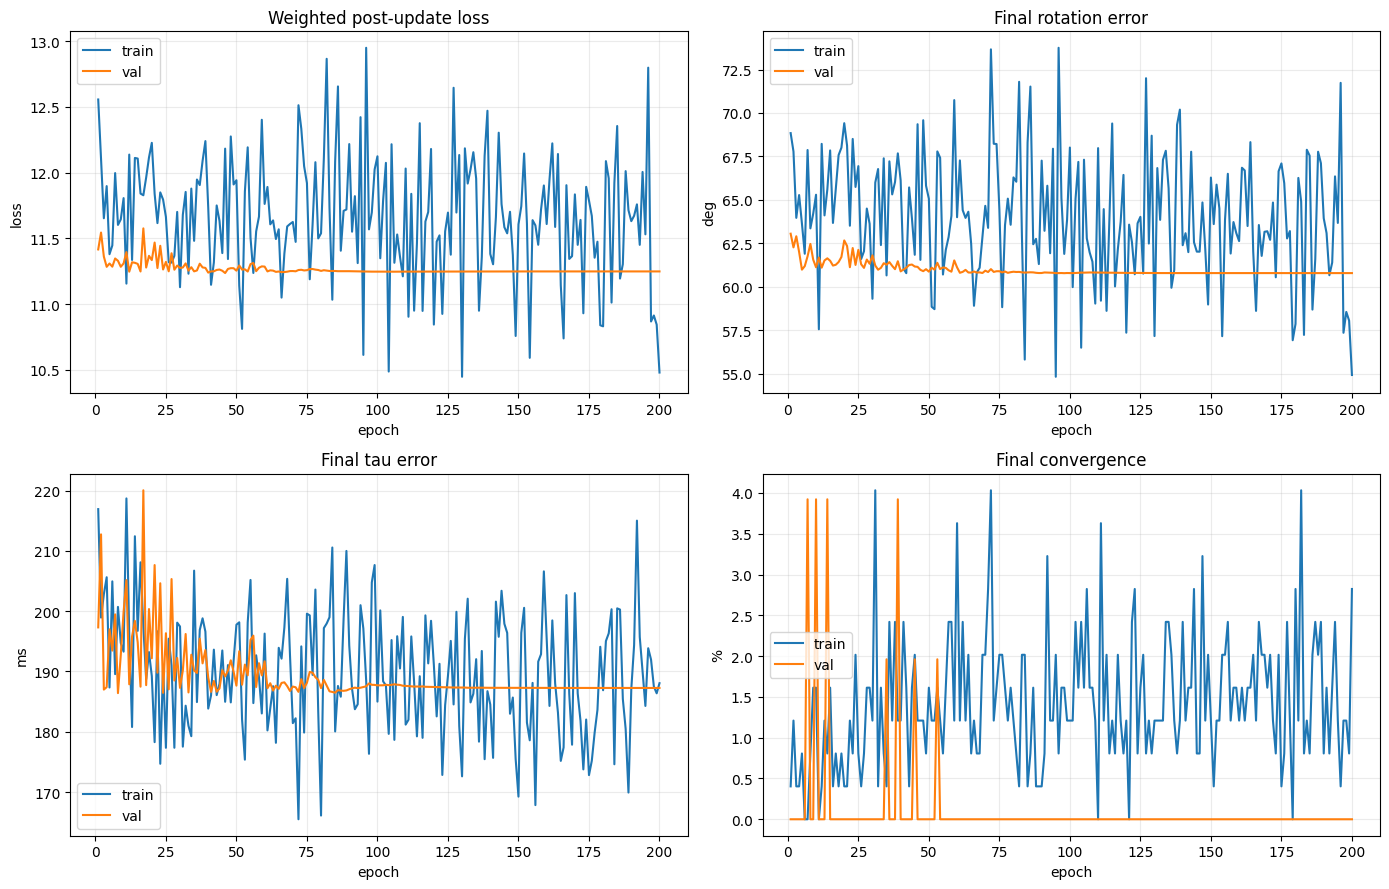

Verified: best.pt epoch 46
Verified: last.pt epoch 200


In [30]:
if history:
    epochs = [h["epoch"] for h in history]
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for split in ("train", "val"):
        axes[0,0].plot(epochs, [h[f"{split}/loss_total"] for h in history], label=split)
        axes[0,1].plot(epochs, [h[f"{split}/final_rotation_deg"] for h in history], label=split)
        axes[1,0].plot(epochs, [h[f"{split}/final_tau_ms"] for h in history], label=split)
        axes[1,1].plot(epochs, [100*h[f"{split}/final_converged"] for h in history], label=split)
    for ax, name, unit in zip(axes.ravel(), ("Weighted post-update loss", "Final rotation error", "Final tau error", "Final convergence"), ("loss", "deg", "ms", "%")):
        ax.set_title(name); ax.set_ylabel(unit); ax.set_xlabel("epoch"); ax.grid(alpha=.25); ax.legend()
    fig.tight_layout(); plt.show()

from obscalib.training.checkpoint import read_training_checkpoint
for path in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH):
    if path.is_file():
        payload = read_training_checkpoint(path, map_location="cpu")
        snapshot = (payload.get("extra_state") or {}).get("experiment")
        assert isinstance(snapshot, dict) and snapshot["run_name"] == RUN_NAME
        assert isinstance(snapshot["model_config"], PooledCalibrationModelConfig)
        # assert snapshot["gradient_horizon_windows"] == 1
        print("Verified:", path.name, "epoch", payload.get("epoch"))
        del payload

## 14. Identically seeded held-out evaluation of source and fine-tuned checkpoints

In [31]:
def evaluate_checkpoint_rollout(checkpoint_path, loader, seed, *, label):
    load_training_checkpoint(checkpoint_path, model=model, map_location=DEVICE, restore_rng_state=False)
    metrics, _ = run_rollout_epoch(loader, training=False, generator=make_augmentation_generator(seed), label=label)
    return metrics

if BEST_CHECKPOINT_PATH.is_file():
    source_test_metrics = evaluate_checkpoint_rollout(INITIAL_CHECKPOINT, sequence_test_loader, TEST_SEQUENCE_SEED, label="Source test")
    trained_test_metrics = evaluate_checkpoint_rollout(BEST_CHECKPOINT_PATH, sequence_test_loader, TEST_SEQUENCE_SEED, label="Fine-tuned test")
    print(f"{'metric':30s} {'source':>12s} {'trained':>12s}")
    for key in ("loss_total", "initial_rotation_deg", "final_rotation_deg", "initial_tau_ms", "final_tau_ms", "final_converged", "final_rotation_improvement", "final_tau_improvement"):
        print(f"{key:30s} {source_test_metrics[key]:12.4f} {trained_test_metrics[key]:12.4f}")
    print("\nConvergence by fault type:")
    for fault_type in ("rotation_only", "tau_only", "combined"):
        stem = f"mode/{fault_type}/"
        print(f"{fault_type:14s}: source {100*source_test_metrics[stem+'final_converged']:.1f}%, trained {100*trained_test_metrics[stem+'final_converged']:.1f}%")
    print("\nRotation error by initial-angle band:")
    for band in ("0-5", "5-30", "30-60", "60-90", "90-130", "130-170.1"):
        key = f"angle/{band}/final_rotation_deg"
        print(f"{band:9s}: N={trained_test_metrics[f'angle/{band}/count']:.0f}, source={source_test_metrics[key]:.2f} deg, trained={trained_test_metrics[key]:.2f} deg")
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
else:
    print("No fine-tuned checkpoint. Run full training or set RUN_FULL_TRAINING=True.")

metric                               source      trained
loss_total                           6.4651      11.5481
initial_rotation_deg                62.9780      62.9780
final_rotation_deg                  48.5962      63.6335
initial_tau_ms                     185.9091     185.9091
final_tau_ms                         8.6388     188.4694
final_converged                      0.5116       0.0349
final_rotation_improvement          14.3818      -0.6555
final_tau_improvement              177.2703      -2.5603

Convergence by fault type:
rotation_only : source 38.1%, trained 0.0%
tau_only      : source 73.3%, trained 10.0%
combined      : source 40.0%, trained 0.0%

Rotation error by initial-angle band:
0-5      : N=0, source=nan deg, trained=nan deg
5-30     : N=6, source=2.92 deg, trained=15.95 deg
30-60    : N=9, source=2.23 deg, trained=46.98 deg
60-90    : N=5, source=14.00 deg, trained=76.94 deg
90-130   : N=22, source=80.38 deg, trained=107.20 deg
130-170.1: N=14, source=159.99 deg

## 15. Signed-axis rollout trajectories: source versus trained checkpoint

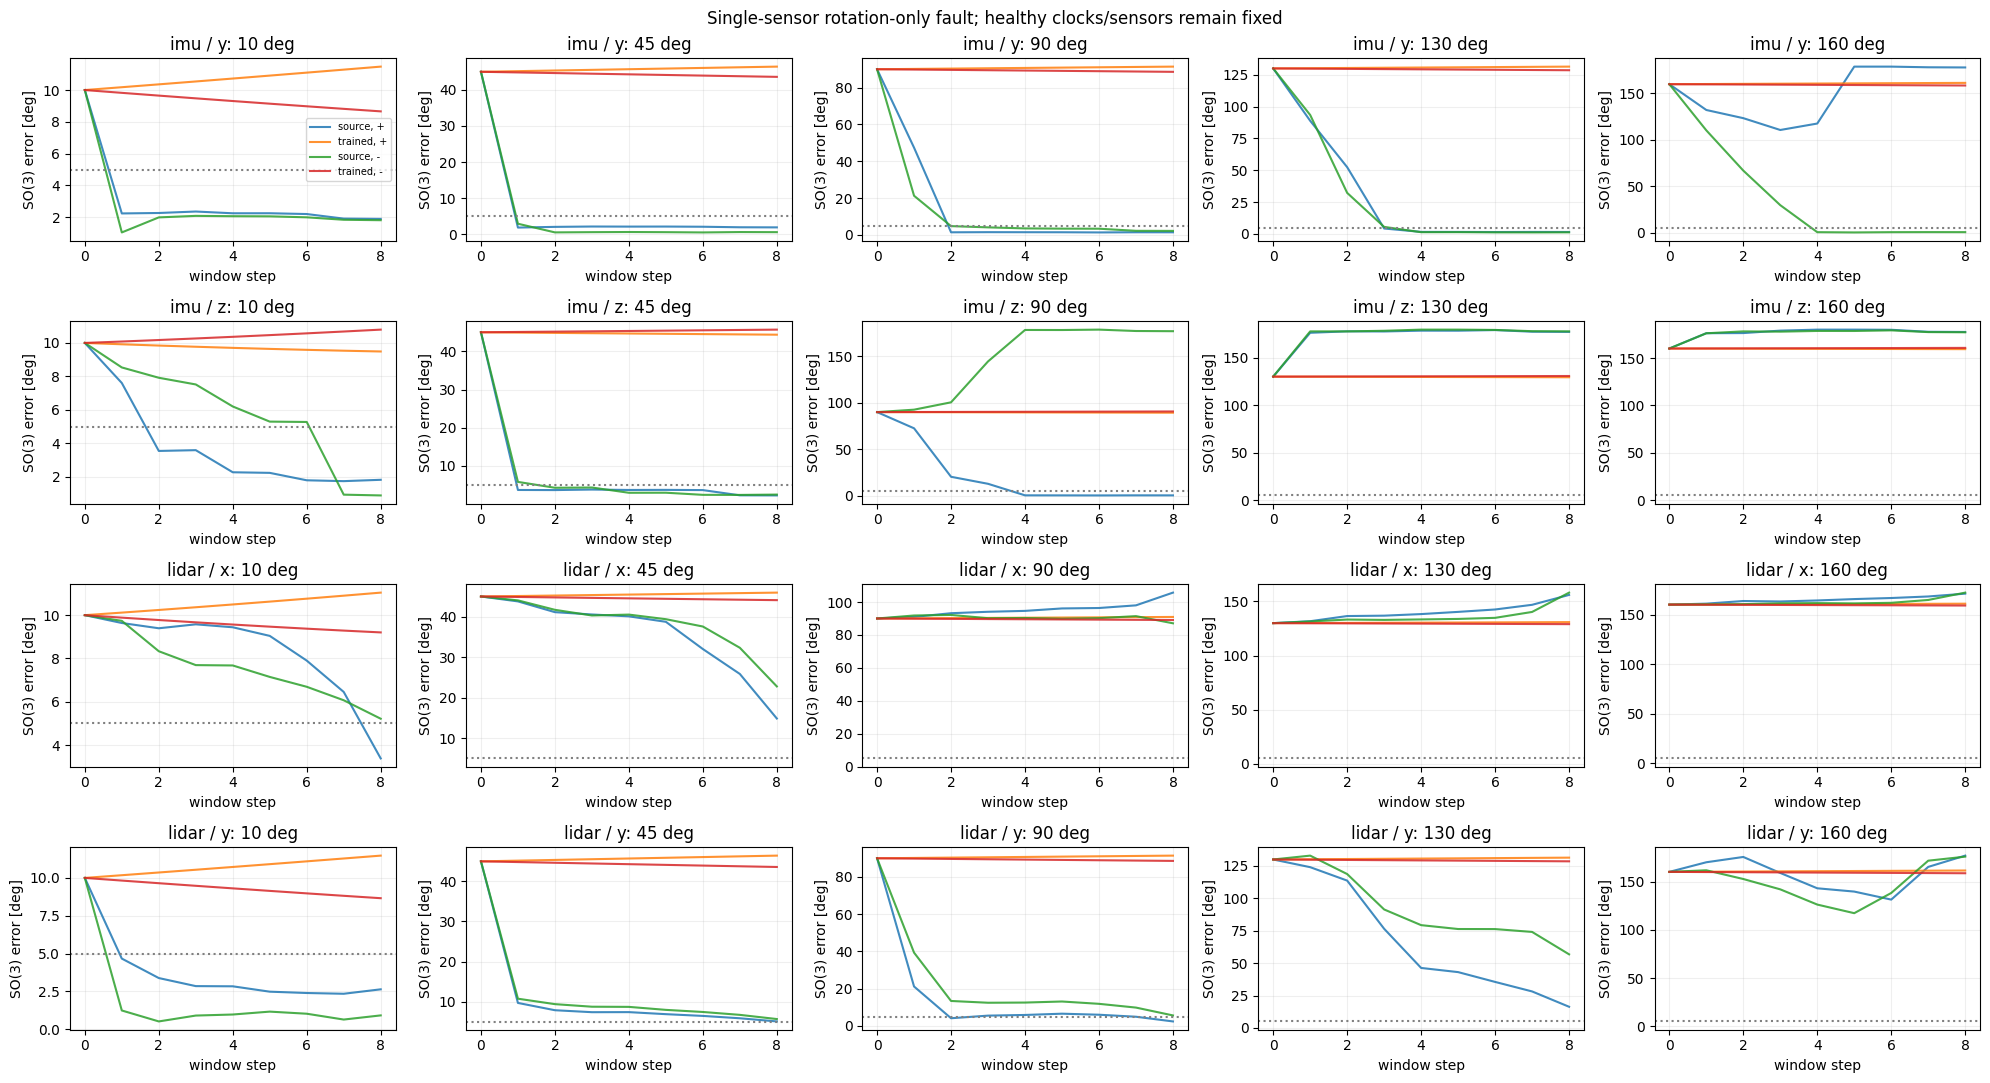

In [32]:
# Keep this diagnostic much smaller than exhaustive 3 x 3 x many-angle testing.
DIAGNOSTIC_SENSOR_AXES = (("imu", 1), ("imu", 2), ("lidar", 0), ("lidar", 1))       # ("lidar_right", 0), 
DIAGNOSTIC_INITIAL_ANGLES = (10.0, 45.0, 90.0, 130.0, 160.0)
DIAGNOSTIC_SIGNS = (1.0, -1.0)
DIAGNOSTIC_TEST_CHUNK_INDEX = 0

@torch.inference_mode()
def trace_fixed_axis_case(sequence_batches, sensor, axis, signed_degrees):
    first = window_batch_to(sequence_batches[0], DEVICE, dtype=MODEL_DTYPE)
    truth = detach_calibration(first.current_calibration)
    B = truth[sensor].transform.shape[0]
    if B != 1: raise ValueError("Trace one physical sequence at a time.")
    states = copy_calibration(truth)
    dr = torch.zeros((B,3), dtype=MODEL_DTYPE, device=DEVICE)
    dr[:,axis] = np.deg2rad(signed_degrees)
    states[sensor].transform[:, :3, :3] = so3_exp(dr) @ truth[sensor].transform[:, :3, :3]
    selected = {k: torch.full((B,), k==sensor, dtype=torch.bool, device=DEVICE) for k in CALIBRATION_KEYS}
    initial_rot, _ = initial_state_errors(truth, states, selected)
    errors = [float(initial_rot[0])]
    for t, cpu_step in enumerate(sequence_batches):
        step = first if t==0 else window_batch_to(cpu_step, DEVICE, dtype=MODEL_DTYPE)
        output = rollout_forward(step, states)
        states = detach_calibration(apply_rollout_correction(states, output, selected))
        _, rot, _ = rollout_state_loss(truth, states, selected)
        errors.append(float(rot[0]))
    return errors

if BEST_CHECKPOINT_PATH.is_file():
    singleton_sequence = collate_kaist_sequence_chunks([sequence_test_dataset[DIAGNOSTIC_TEST_CHUNK_INDEX]])
    traces = {}
    for label, path in (("source", INITIAL_CHECKPOINT), ("trained", BEST_CHECKPOINT_PATH)):
        load_training_checkpoint(path, model=model, map_location=DEVICE, restore_rng_state=False)
        model.eval()
        for sensor, axis in DIAGNOSTIC_SENSOR_AXES:
            for angle in DIAGNOSTIC_INITIAL_ANGLES:
                for sign in DIAGNOSTIC_SIGNS:
                    case = (sensor, axis, float(sign*angle))
                    traces[(label, *case)] = trace_fixed_axis_case(singleton_sequence, *case)
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)

    fig, axes = plt.subplots(len(DIAGNOSTIC_SENSOR_AXES), len(DIAGNOSTIC_INITIAL_ANGLES), figsize=(20, 11), squeeze=False)
    for i, (sensor, axis) in enumerate(DIAGNOSTIC_SENSOR_AXES):
        for j, angle in enumerate(DIAGNOSTIC_INITIAL_ANGLES):
            ax = axes[i,j]
            for sign in DIAGNOSTIC_SIGNS:
                for label in ("source", "trained"):
                    curve = traces[(label, sensor, axis, sign*angle)]
                    ax.plot(range(len(curve)), curve, label=f"{label}, {'+' if sign>0 else '-'}", alpha=.85)
            ax.axhline(CONVERGENCE_ROTATION_DEG, color="gray", linestyle=":")
            ax.set_title(f"{sensor} / {'xyz'[axis]}: {angle:g} deg")
            ax.set_xlabel("window step"); ax.set_ylabel("SO(3) error [deg]"); ax.grid(alpha=.2)
            if i==0 and j==0: ax.legend(fontsize=7)
    fig.suptitle("Single-sensor rotation-only fault; healthy clocks/sensors remain fixed")
    fig.tight_layout(); plt.show()
else:
    print("Training checkpoint missing; signed-axis comparisons skipped.")

In [33]:
torch.cuda.empty_cache()

## 16. Interpretation and horizon comparison

This experiment changes **backpropagation credit assignment**, not the rollout dynamics: the network still corrects an eight-window sequence, and the physical calibration is carried into every next window.

- **Promote only if** held-out rotation-only and mixed-fault rollouts improve, not merely aggregate time-offset loss. The source-vs-trained comparison, angle-band breakdown and signed-axis traces are unchanged from notebook 34.
- The validation/test trajectory is *identical* for `BPTT_HORIZON=1`, `3`, and `8` for the same model weights, because evaluation never backpropagates. Only the learned weights change with the gradient horizon.
- **Memory:** expect activation memory to grow roughly with `SEQUENCE_BATCH_SIZE * BPTT_HORIZON`; there is also fixed model/optimizer state, token-length-dependent attention, and temporary geometry/autograd memory. Use measured `peak_allocated_gib` rather than relying on a linear formula.
- **Time:** reducing batch size from 16 to 2 increases sequence batches and optimizer updates per epoch dramatically; eight-window backpropagation also retains activations longer. Full `H=8, B=2` can be materially slower than the notebook 34 configuration even when it fits VRAM.
- Recommended first comparison: `H=3, B=4`, initialized from `002.16/best.pt`, with `LEARNING_RATE=1e-5`. If it outperforms the `H=1` baseline, try `H=8, B=2` as a separate run with its own `RUN_NAME`.
- A positive smoke test proves differentiable temporal coupling, not that all physical calibration directions are observable. Very large rotations near 180° can still create inaccurate gradients or incorrect attractors. Guard against nonfinite gradients and inspect held-out rollouts.

**Resume note:** Set `RESUME_TRAINING=True` only when the horizon, sequence length and batch size match the checkpoint. Resume restores model, optimizer, scheduler and sampling generators; starting a new horizon should use a fresh run directory and initialize model weights from the chosen source checkpoint.
